# BRCA ST patient C — pan-cancer Hist2Pheno

Andersson et al. *Nat Commun* 2021. HER2ST **C**: patient 5714, sections C1–C6, about 0.69 µm/px. No cell-type ground truth.
Predictions are the pan-cancer **cross-section** checkpoint `D_emph_L2_spatial_pancancer` (L1 / L12 / L2), spatial k=8.

JPEG 72 dpi is not used. µm/px is the 200 µm ST spot pitch. UNI rescales by `mpp/0.5` so the 16 px crop is **8 µm**.

One notebook per patient so the file does not store all 36 slides. Full-resolution PNGs stay in `data/ST/BRCA/pred_pancancer_section/figures/`.

```bash
SAMPLE=C bash code/External_val/BRCA_ST/demo.sh all
```


In [1]:
import io
import shutil
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, Markdown, display
from PIL import Image as PILImage

REPO = Path("/home/lingyu/ssd2/Python/Hist2Pheno")
if not (REPO / "code").is_dir():
    REPO = Path("/nobackup2/users/lingyu/Python/Hist2Pheno")
sys.path.insert(0, str(REPO / "code" / "External_val" / "BRCA_ST"))

from brca_st_external import (  # noqa: E402
    PRED_ROOT,
    composition_table,
    discover_samples,
    geometry,
    sample_paths,
    ensure_l2_probs,
    cmd_plot,
)

PATIENT = "C"
PREVIEW_PX = 1100
group = discover_samples(PATIENT)
fig_dir = PRED_ROOT / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)
print(f"{PATIENT}  n={len(group)}")
for sample in group:
    g = geometry(sample)
    print(
        f"{sample}  mpp={g['mpp_um']:.4f} µm/px  "
        f"native16={g['patch_um_if_native_16px']:.2f} µm  "
        f"after rescale={g['patch_um_after_rescale']:.1f} µm  "
        f"scale={g['scale']:.4f}  ({g['mpp_source']})"
    )
    print(f"  pred exists: {sample_paths(sample)['pred'].is_file()}")


def show_preview(path: Path) -> None:
    """Embed a small JPEG. The full PNG stays on disk."""
    im = PILImage.open(path)
    im.thumbnail((PREVIEW_PX, PREVIEW_PX))
    buf = io.BytesIO()
    im.convert("RGB").save(buf, format="JPEG", quality=70)
    display(Image(data=buf.getvalue(), format="jpeg"))
    print(path)


C  n=6
5714_HE_BT_C1  mpp=0.6881 µm/px  native16=11.01 µm  after rescale=8.0 µm  scale=1.3761  (ST 200 µm spot pitch (C1))
  pred exists: True
5714_HE_BT_C2  mpp=0.6899 µm/px  native16=11.04 µm  after rescale=8.0 µm  scale=1.3798  (ST 200 µm spot pitch (C2))
  pred exists: True
5714_HE_BT_D1  mpp=0.6878 µm/px  native16=11.00 µm  after rescale=8.0 µm  scale=1.3756  (ST 200 µm spot pitch (C3))
  pred exists: True
5714_HE_BT_D2  mpp=0.6855 µm/px  native16=10.97 µm  after rescale=8.0 µm  scale=1.3710  (ST 200 µm spot pitch (C4))
  pred exists: True
5714_HE_BT_E1  mpp=0.6834 µm/px  native16=10.93 µm  after rescale=8.0 µm  scale=1.3669  (ST 200 µm spot pitch (C5))
  pred exists: True
5714_HE_BT_E2  mpp=0.6873 µm/px  native16=11.00 µm  after rescale=8.0 µm  scale=1.3746  (ST 200 µm spot pitch (C6))
  pred exists: True


## C — composition and spatial labels


===== C L1 =====


fraction                                            \
sample      5714_HE_BT_C1 5714_HE_BT_C2 5714_HE_BT_D1 5714_HE_BT_D2   
class                                                                 
Immune              0.581         0.645         0.594         0.632   
Endothelial         0.241         0.179         0.247         0.227   
Stromal             0.171         0.173         0.153         0.132   
Epithelial          0.007         0.003         0.005         0.009   
Neural              0.000           NaN           NaN           NaN   

                                            mean_conf                \
sample      5714_HE_BT_E1 5714_HE_BT_E2 5714_HE_BT_C1 5714_HE_BT_C2   
class                                                                 
Immune              0.593         0.686         0.597         0.616   
Endothelial         0.278         0.195         0.457         0.462   
Stromal             0.123         0.115         0.443         0.459   
Epithelial          0.007         0.003         0.418         0.415   
Neural                NaN           NaN         0.353           NaN   

                                                                     \
sample      5714_HE_BT_D1 5714_HE_BT_D2 5714_HE_BT_E1 5714_HE_BT_E2   
class                                                                 
Immune              0.603         0.601         0.611         0.641   
Endothelial         0.461         0.452         0.469         0.472   
Stromal             0.439         0.433         0.437         0.445   
Epithelial          0.420         0.462         0.453         0.448   
Neural                NaN           NaN           NaN           NaN   

                        n                                            \
sample      5714_HE_BT_C1 5714_HE_BT_C2 5714_HE_BT_D1 5714_HE_BT_D2   
class                                                                 
Immune            15713.0       19875.0       17116.0       17839.0   
Endothelial        6516.0        5522.0        7118.0        6403.0   
Stromal            4614.0        5328.0        4408.0        3721.0   
Epithelial          179.0          79.0         156.0         257.0   
Neural                1.0           NaN           NaN           NaN   

                                         
sample      5714_HE_BT_E1 5714_HE_BT_E2  
class                                    
Immune            16565.0       22487.0  
Endothelial        7756.0        6394.0  
Stromal            3425.0        3783.0  
Epithelial          198.0         114.0  
Neural                NaN           NaN

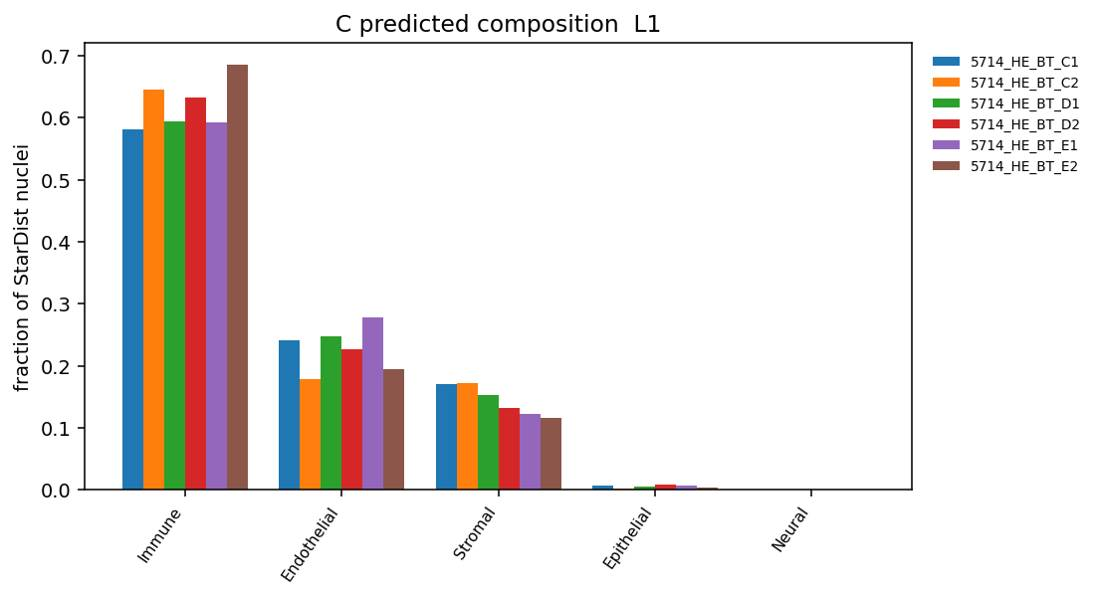

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/C_composition_L1.png

===== C L12 =====


fraction                                            \
sample      5714_HE_BT_C1 5714_HE_BT_C2 5714_HE_BT_D1 5714_HE_BT_D2   
class                                                                 
T_cell              0.684         0.756         0.712         0.732   
Stromal             0.235         0.187         0.210         0.188   
B_Plasma            0.027         0.024         0.030         0.034   
Endothelial         0.024         0.019         0.027         0.021   
Myeloid             0.025         0.012         0.016         0.017   
Epithelial          0.005         0.002         0.004         0.006   
Tumor               0.001         0.000         0.000         0.001   

                                            mean_conf                \
sample      5714_HE_BT_E1 5714_HE_BT_E2 5714_HE_BT_C1 5714_HE_BT_C2   
class                                                                 
T_cell              0.694         0.772         0.481         0.504   
Stromal             0.200         0.146         0.370         0.378   
B_Plasma            0.042         0.040         0.390         0.401   
Endothelial         0.037         0.028         0.328         0.320   
Myeloid             0.020         0.010         0.304         0.303   
Epithelial          0.006         0.004         0.353         0.356   
Tumor               0.001         0.000         0.358         0.317   

                                                                     \
sample      5714_HE_BT_D1 5714_HE_BT_D2 5714_HE_BT_E1 5714_HE_BT_E2   
class                                                                 
T_cell              0.479         0.475         0.481         0.515   
Stromal             0.366         0.359         0.357         0.358   
B_Plasma            0.407         0.413         0.409         0.442   
Endothelial         0.332         0.327         0.325         0.324   
Myeloid             0.292         0.291         0.289         0.285   
Epithelial          0.344         0.377         0.365         0.361   
Tumor               0.403         0.393         0.442         0.387   

                        n                                            \
sample      5714_HE_BT_C1 5714_HE_BT_C2 5714_HE_BT_D1 5714_HE_BT_D2   
class                                                                 
T_cell            18479.0       23290.0       20507.0       20656.0   
Stromal            6353.0        5745.0        6045.0        5310.0   
B_Plasma            722.0         743.0         855.0         966.0   
Endothelial         652.0         584.0         789.0         600.0   
Myeloid             679.0         364.0         466.0         482.0   
Epithelial          124.0          65.0         127.0         182.0   
Tumor                14.0          13.0           9.0          24.0   

                                         
sample      5714_HE_BT_E1 5714_HE_BT_E2  
class                                    
T_cell            19402.0       25316.0  
Stromal            5592.0        4777.0  
B_Plasma           1181.0        1304.0  
Endothelial        1029.0         906.0  
Myeloid             550.0         331.0  
Epithelial          172.0         135.0  
Tumor                18.0           9.0

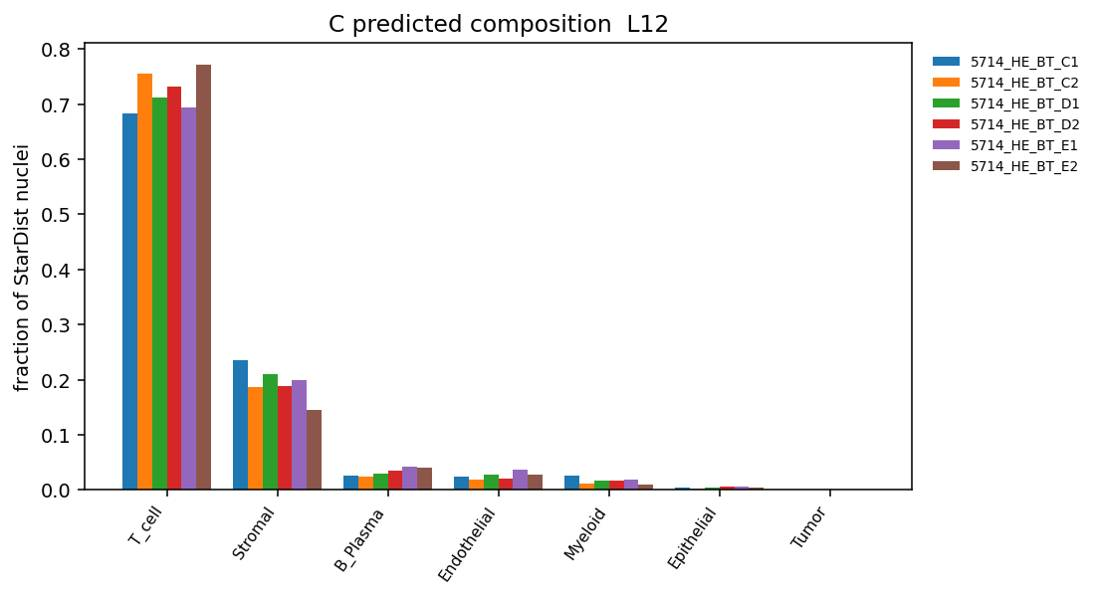

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/C_composition_L12.png

===== C L2 =====


fraction                                            \
sample            5714_HE_BT_C1 5714_HE_BT_C2 5714_HE_BT_D1 5714_HE_BT_D2   
class                                                                       
B_cell                    0.518         0.548         0.535         0.600   
CD4_T                     0.130         0.170         0.128         0.111   
Fibroblast                0.161         0.151         0.151         0.127   
Endothelial               0.111         0.080         0.119         0.098   
CD8_T                     0.036         0.010         0.032         0.032   
Stromal                   0.023         0.023         0.016         0.016   
Plasma                    0.008         0.005         0.008         0.006   
Neutrophil                0.006         0.006         0.004         0.003   
Tregs                     0.000         0.005         0.000         0.000   
Injury_epithelial         0.002         0.001         0.002         0.002   
Epithelial                0.002         0.001         0.002         0.002   
DC                        0.001         0.001         0.001         0.001   
Tumor                     0.001         0.000         0.000         0.001   
Macrophage                0.000         0.000         0.000         0.000   
Myoepithelial             0.000         0.000         0.000         0.000   
DCIS                      0.000         0.000         0.000         0.000   
Myofibroblast             0.000           NaN         0.000         0.000   
Alveolar                    NaN           NaN           NaN         0.000   

                                                  mean_conf                \
sample            5714_HE_BT_E1 5714_HE_BT_E2 5714_HE_BT_C1 5714_HE_BT_C2   
class                                                                       
B_cell                    0.539         0.566         0.375         0.392   
CD4_T                     0.124         0.172         0.293         0.318   
Fibroblast                0.126         0.117         0.255         0.270   
Endothelial               0.138         0.094         0.257         0.258   
CD8_T                     0.031         0.014         0.245         0.233   
Stromal                   0.019         0.014         0.310         0.305   
Plasma                    0.012         0.009         0.225         0.241   
Neutrophil                0.006         0.007         0.233         0.217   
Tregs                     0.000         0.004         0.212         0.249   
Injury_epithelial         0.003         0.001         0.256         0.266   
Epithelial                0.002         0.002         0.223         0.226   
DC                        0.000         0.000         0.230         0.263   
Tumor                     0.001         0.000         0.291         0.272   
Macrophage                0.000         0.000         0.180         0.167   
Myoepithelial             0.000           NaN         0.203         0.177   
DCIS                      0.000         0.000         0.247         0.330   
Myofibroblast             0.000           NaN         0.233           NaN   
Alveolar                    NaN           NaN           NaN           NaN   

                                                                           \
sample            5714_HE_BT_D1 5714_HE_BT_D2 5714_HE_BT_E1 5714_HE_BT_E2   
class                                                                       
B_cell                    0.389         0.392         0.398         0.415   
CD4_T                     0.292         0.289         0.298         0.325   
Fibroblast                0.253         0.250         0.253         0.258   
Endothelial               0.257         0.253         0.262         0.265   
CD8_T                     0.241         0.232         0.241         0.242   
Stromal                   0.287         0.279         0.297         0.287   
Plasma                    0.240         0.249         0.244         0.233   
Neutrophil       

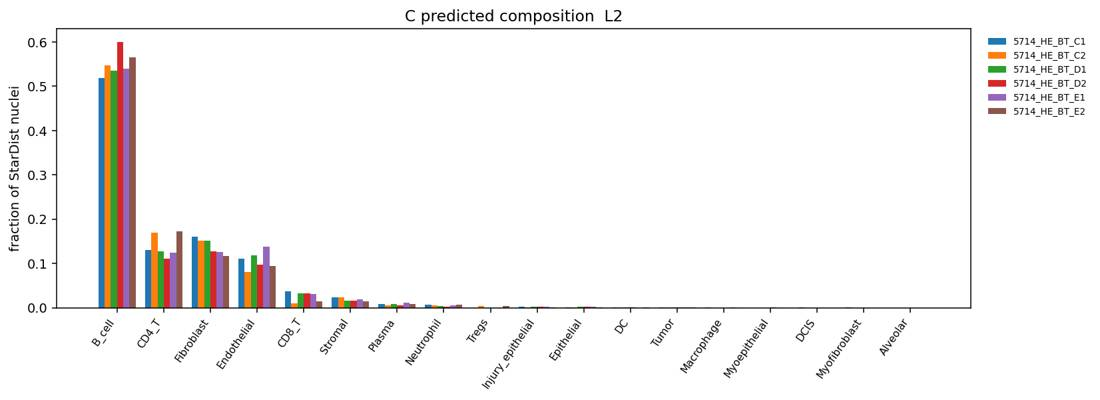

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/C_composition_L2.png
5714_HE_BT_C1


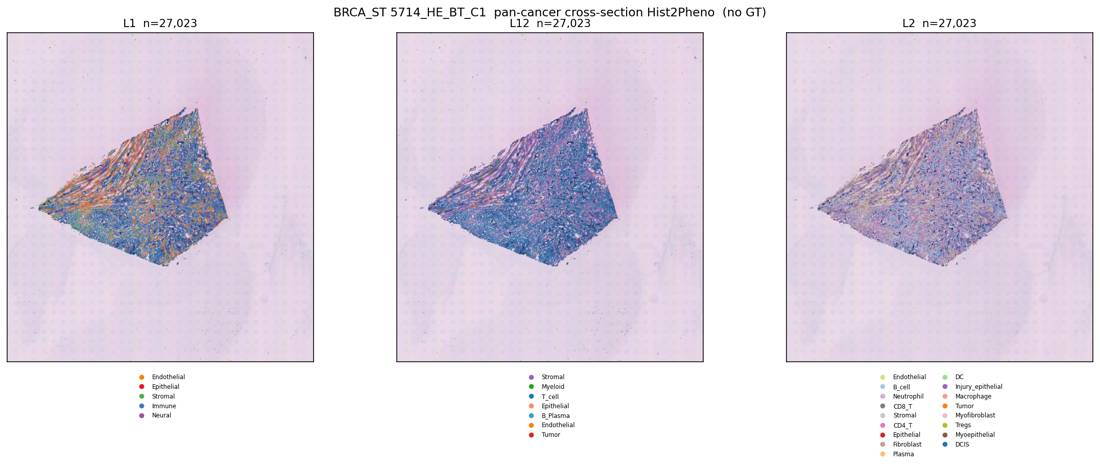

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/5714_HE_BT_C1_spatial_L1_L12_L2.png
5714_HE_BT_C2


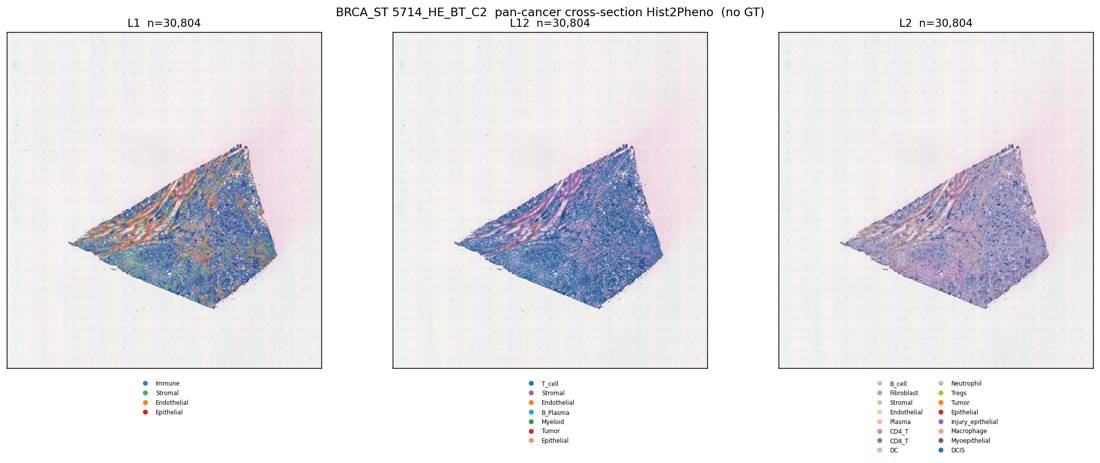

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/5714_HE_BT_C2_spatial_L1_L12_L2.png
5714_HE_BT_D1


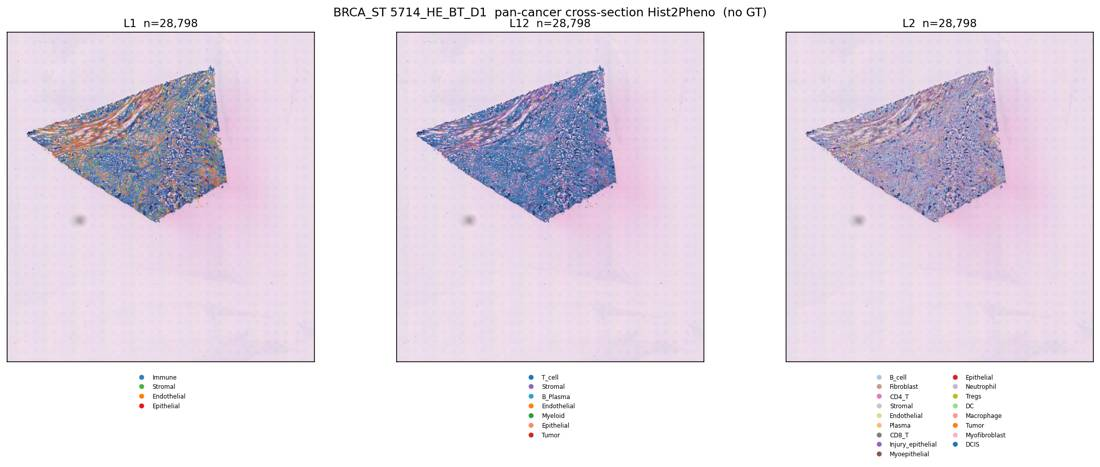

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/5714_HE_BT_D1_spatial_L1_L12_L2.png
5714_HE_BT_D2


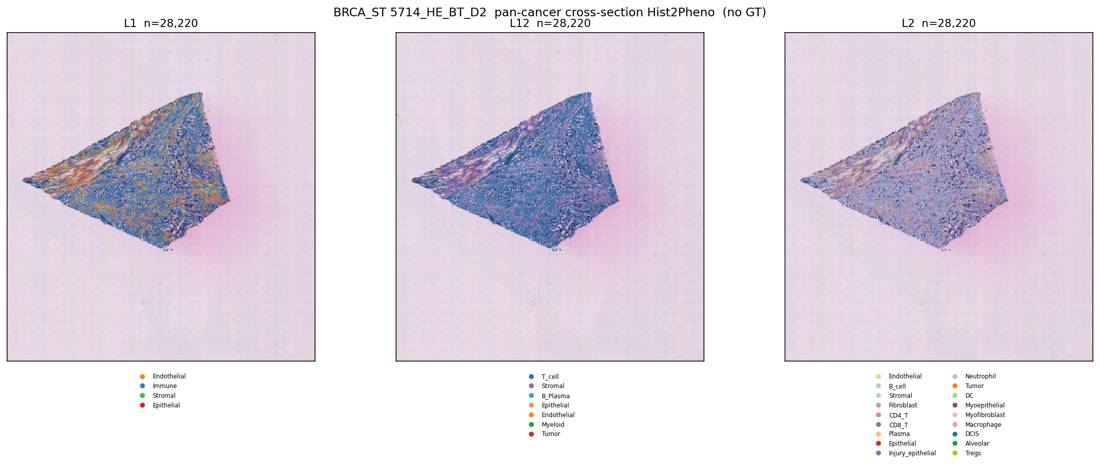

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/5714_HE_BT_D2_spatial_L1_L12_L2.png
5714_HE_BT_E1


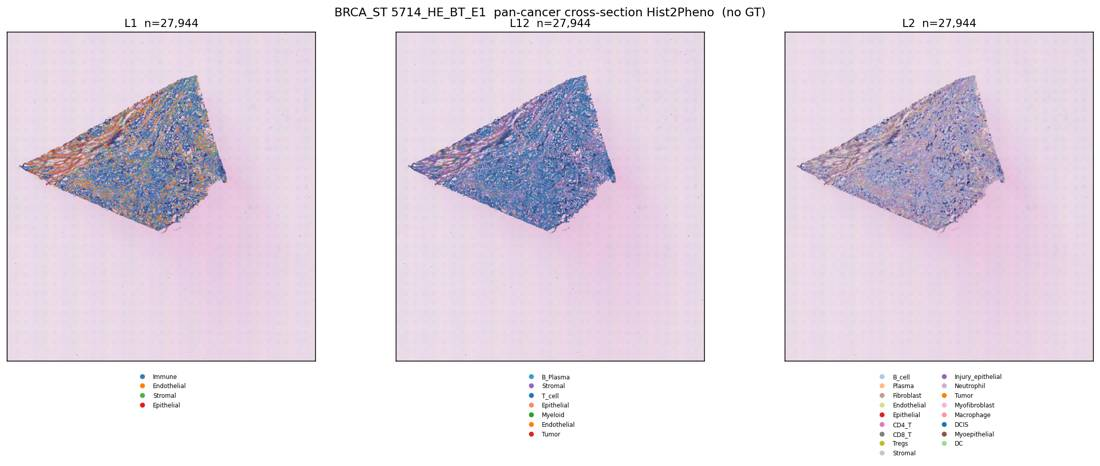

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/5714_HE_BT_E1_spatial_L1_L12_L2.png
5714_HE_BT_E2


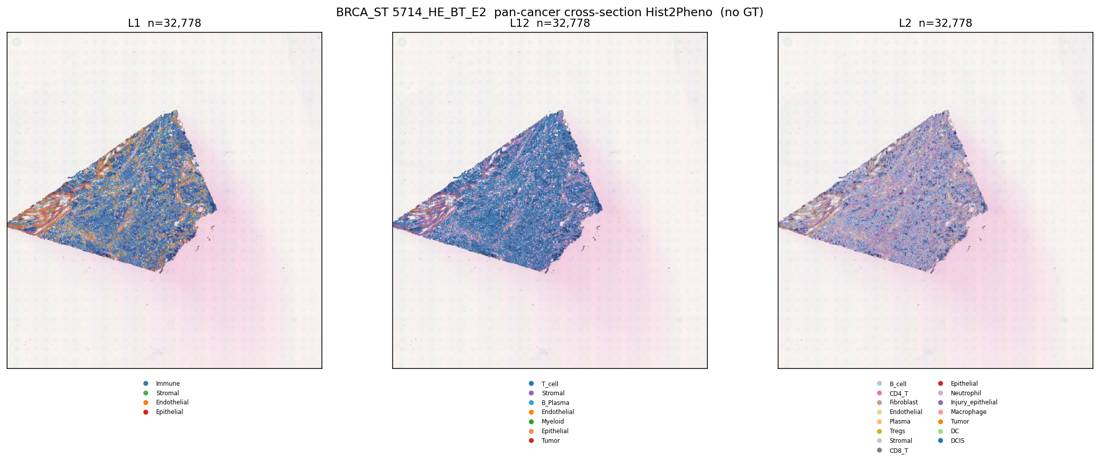

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/5714_HE_BT_E2_spatial_L1_L12_L2.png


In [2]:
missing = [s for s in group if not sample_paths(s)["pred"].is_file()]
if missing:
    raise FileNotFoundError(
        f"No predictions yet for {PATIENT}: "
        + ", ".join(missing)
        + f". Run: SAMPLE={PATIENT} bash code/External_val/BRCA_ST/demo.sh all"
    )

display(Markdown(f"## {PATIENT} — composition and spatial labels"))
comp = composition_table(group)
for head in ("L1", "L12", "L2"):
    sub = comp.loc[comp["head"] == head].copy()
    order = sub.groupby("class")["fraction"].max().sort_values(ascending=False).index
    wide = (
        sub.pivot_table(index="class", columns="sample", values=["fraction", "n", "mean_conf"])
        .reindex(order)
    )
    print(f"\n===== {PATIENT} {head} =====")
    display(wide.round(3))

    classes = list(order)
    sections = list(dict.fromkeys(sub["sample"]))
    fig, ax = plt.subplots(figsize=(max(8, 0.55 * len(classes) + 2), 4.4))
    x = range(len(classes))
    width = 0.8 / max(len(sections), 1)
    for i, section in enumerate(sections):
        ss = sub.loc[sub["sample"] == section].set_index("class")
        vals = [float(ss.loc[c, "fraction"]) if c in ss.index else 0.0 for c in classes]
        ax.bar([xi + i * width for xi in x], vals, width=width, label=section)
    ax.set_xticks([xi + width * (len(sections) - 1) / 2 for xi in x])
    ax.set_xticklabels(classes, rotation=55, ha="right", fontsize=8)
    ax.set_ylabel("fraction of StarDist nuclei")
    ax.set_title(f"{PATIENT} predicted composition  {head}")
    ax.legend(frameon=False, fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1))
    fig.tight_layout()
    out = fig_dir / f"{PATIENT}_composition_{head}.png"
    fig.savefig(out, dpi=140, bbox_inches="tight")
    plt.close(fig)
    show_preview(out)

spatial_missing = [
    s for s in group if not (fig_dir / f"{s}_spatial_L1_L12_L2.png").is_file()
]
if spatial_missing:
    cmd_plot(group)
    for head in ("L1", "L12", "L2"):
        src = fig_dir / f"composition_{head}.png"
        if src.is_file():
            shutil.copy(src, fig_dir / f"{PATIENT}_composition_{head}.png")
for sample in group:
    print(sample)
    show_preview(fig_dir / f"{sample}_spatial_L1_L12_L2.png")


## Histology-derived niche indices (TLS / SRI / TNI)

Same implementation as `code/Xenium_lung/histology_derived_niche_index.ipynb` §3, via `Hist2Pheno_pkg/histology_niche_index.py`. Lung ARI / FRI are not used.

Scores use **L2 softmax**, not the argmax label. `ensure_l2_probs` caches `{sample}_l2_probs.npz`.

| Index | Abundance | Spatial (radius R) |
|--|--|--|
| **TLS** | sum(B_cell + Plasma + CD4_T + CD8_T + Tregs + DC) | `(B_local × T_local × DC_local)^(1/3)` |
| **SRI** | (Fibroblast + Myofibroblast + Stromal) / epithelium | Fib_local / Epi_local |
| **TNI** | (fibroblast + Macrophage + Endothelial) / epithelium | `(Fib × Mac × Endo)^(1/3) / Epi_local` |

Epithelium = Epithelial, Tumor, Alveolar, Injury_epithelial, DCIS, Myoepithelial. NK is left out of TLS. `spatial_HE` is native JPEG pixels, so R = **55 µm** uses this slide's own µm/px. TLS, SRI, and TNI are each a 1×3 row. This notebook embeds a resized preview; the saved PNG is full resolution.


In [3]:
import importlib

for _p in (REPO / "code" / "Hist2Pheno_pkg", REPO / "code" / "Xenium_lung"):
    if str(_p) not in sys.path:
        sys.path.insert(0, str(_p))

import histology_niche_index as hni
importlib.reload(hni)
import histology_derived_niche_index as hdni
importlib.reload(hdni)
from histology_niche_index import OrganNicheConfig

import anndata as ad

TLS_RADIUS_UM = 55.0
RECOMPUTE_NICHE = False

BRCA_ST_NICHE = OrganNicheConfig(
    pan_organ="pancancer_brca_st",
    tls_b=("B_cell", "Plasma"),
    tls_t=("CD4_T", "CD8_T", "Tregs"),
    tls_dc=("DC",),
    epithelium=(
        "Epithelial", "Tumor", "Alveolar",
        "Injury_epithelial", "DCIS", "Myoepithelial",
    ),
    fibroblast=("Fibroblast", "Myofibroblast", "Stromal"),
    endothelial=("Endothelial",),
    macrophage=("Macrophage",),
    um_per_he_pixel=float(geometry(group[0])["mpp_um"]),
    spatial_radius_um=TLS_RADIUS_UM,
    cohort="BRCA_ST",
)
display(hni.index_formula_table(BRCA_ST_NICHE))


,index,formula
0,TLS,sum(B_cell+ Plasma+ CD4_T+ CD8_T+ Tregs+ DC)
1,TLS_spatial,(B_local × T_local × DC_local)^(1/3) within ra...
2,SRI_ratio,Fibroblast+Myofibroblast+Stromal / Epithelial+...
3,SRI_spatial,Fib_local / Epi_local within radius R μm
4,TNI_ratio,(Fibroblast+Myofibroblast+Stromal + Macrophage...
5,TNI_spatial,(Fib_local × myeloid_local × Endo_local)^(1/3)...


## C — TLS / SRI / TNI

[probs] cache /nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/5714_HE_BT_C1/5714_HE_BT_C1_l2_probs.npz  (27023, 20)
[niche] wrote /nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/5714_HE_BT_C1/5714_HE_BT_C1_niche_indices.h5ad  n=27,023
  TLS hotspot: {'n_cells_total': 27023, 'n_candidate_cells': 1352, 'fraction_candidate': 0.05003145468674833, 'max_tls_spatial': 0.23669447709338812, 'mean_tls_spatial_candidate': 0.20071606454916585, 'centroid_x': 4825.267230047982, 'centroid_y': 5395.003270846147}
  mean TLS=0.608  TLS_spatial=0.145  SRI=10.326  TNI=18.239
[probs] cache /nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/5714_HE_BT_C2/5714_HE_BT_C2_l2_probs.npz  (30804, 20)
[niche] wrote /nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/5714_HE_BT_C2/5714_HE_BT_C2_niche_indices.h5ad  n=30,804
  TLS hotspot: {'n_cells_total': 30804, 'n_candidate_cells': 1541, 'fraction_candid

,sample,n,TLS_mean,TLS_median,TLS_p95,TLS_max,TLS_spatial_mean,TLS_spatial_median,TLS_spatial_p95,TLS_spatial_max,pearson,spearman,top5_jaccard,abundance_top5_also_spatial_top5,TLS_spatial_mean_in_abundance_top5,TLS_mean_in_spatial_top5
0,5714_HE_BT_C1,27023,0.608,0.634,0.922,0.984,0.145,0.147,0.192,0.237,0.688,0.680,0.113,0.203,0.177,0.836
1,5714_HE_BT_C2,30804,0.642,0.676,0.929,0.989,0.146,0.149,0.181,0.250,0.662,0.642,0.104,0.188,0.170,0.838
2,5714_HE_BT_D1,28798,0.621,0.643,0.931,0.986,0.145,0.148,0.184,0.233,0.661,0.655,0.082,0.152,0.171,0.824
3,5714_HE_BT_D2,28220,0.638,0.670,0.931,0.991,0.149,0.153,0.184,0.220,0.647,0.628,0.070,0.131,0.170,0.809
4,5714_HE_BT_E1,27944,0.620,0.650,0.931,0.985,0.141,0.145,0.179,0.238,0.666,0.661,0.076,0.142,0.166,0.828
5,5714_HE_BT_E2,32778,0.669,0.717,0.946,0.990,0.145,0.150,0.174,0.213,0.657,0.624,0.079,0.146,0.164,0.841


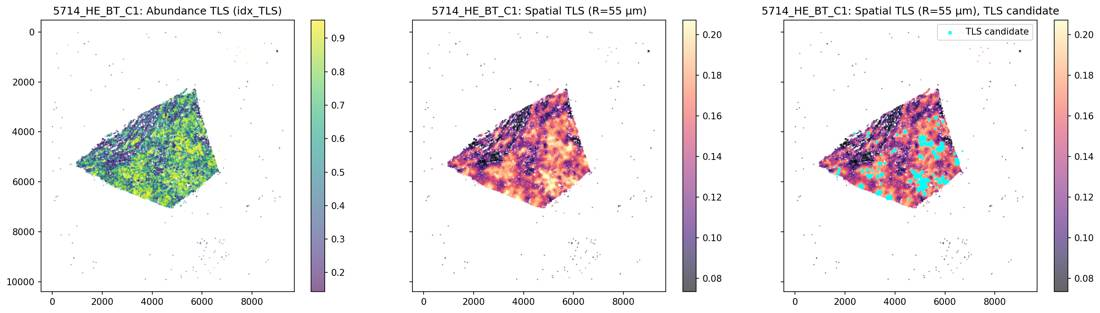

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/5714_HE_BT_C1_TLS_abundance_vs_spatial.png


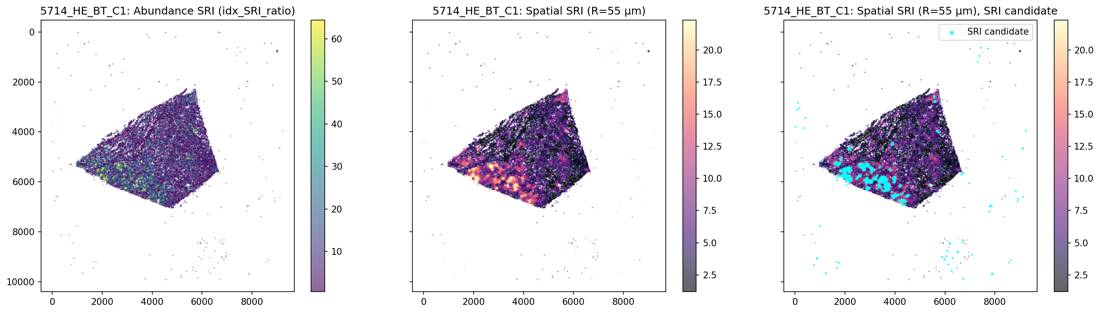

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/5714_HE_BT_C1_SRI_abundance_vs_spatial.png


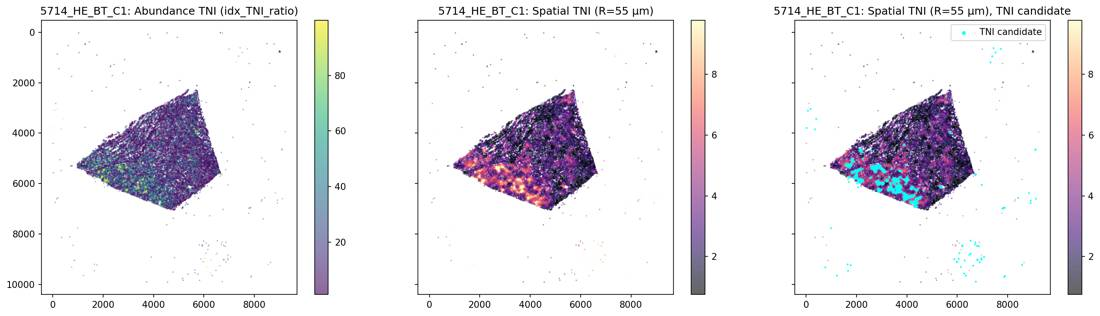

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/5714_HE_BT_C1_TNI_abundance_vs_spatial.png


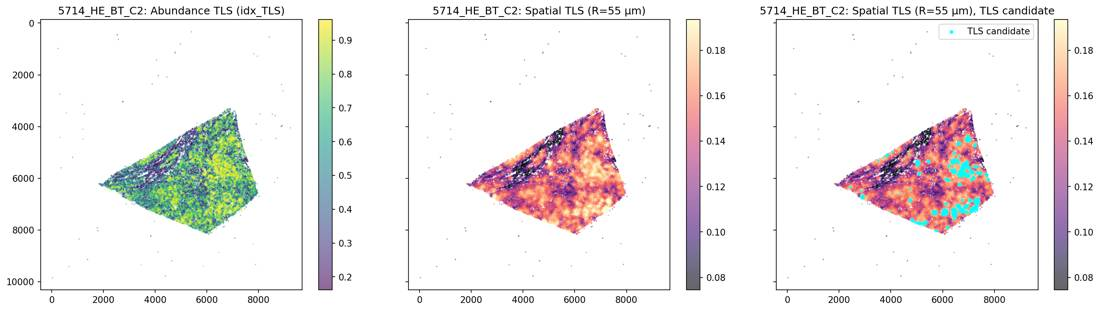

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/5714_HE_BT_C2_TLS_abundance_vs_spatial.png


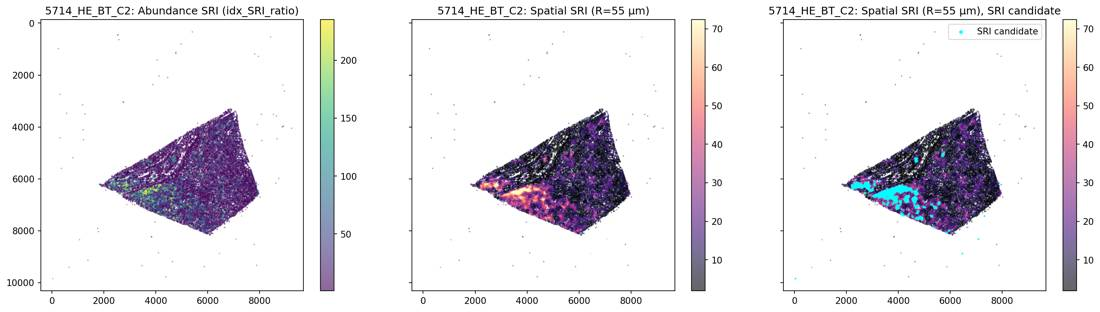

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/5714_HE_BT_C2_SRI_abundance_vs_spatial.png


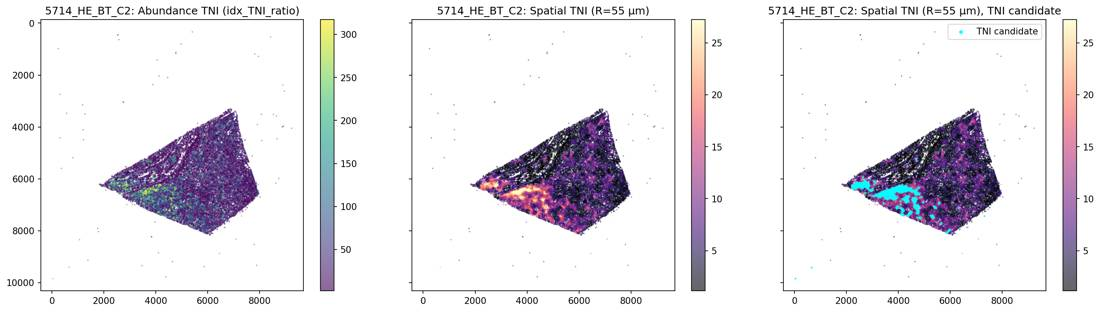

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/5714_HE_BT_C2_TNI_abundance_vs_spatial.png


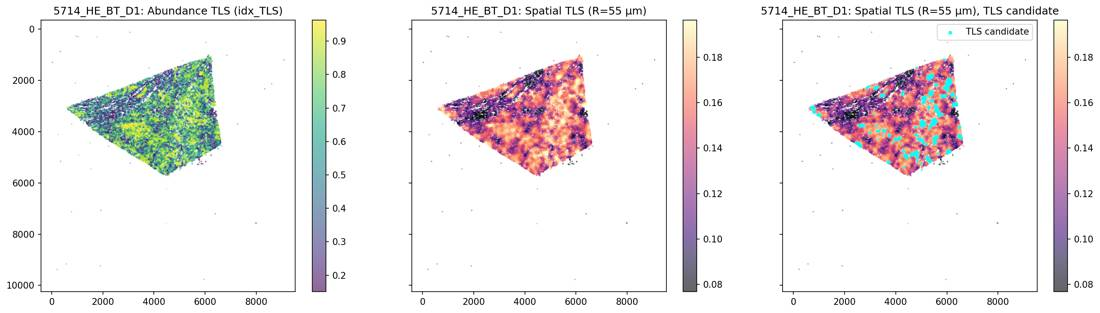

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/5714_HE_BT_D1_TLS_abundance_vs_spatial.png


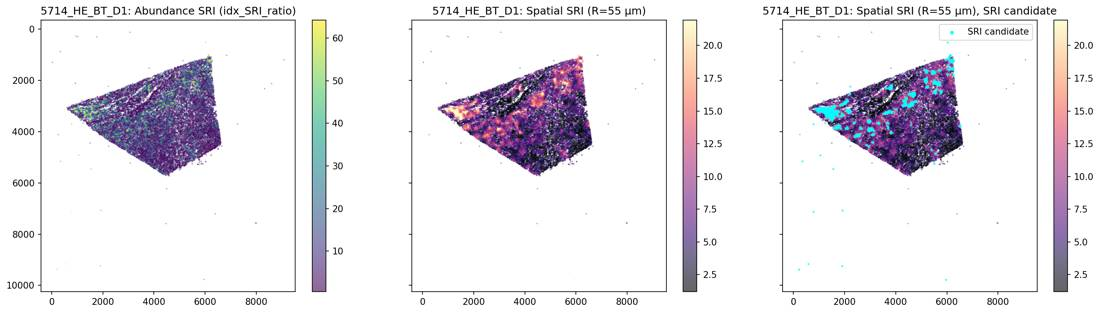

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/5714_HE_BT_D1_SRI_abundance_vs_spatial.png


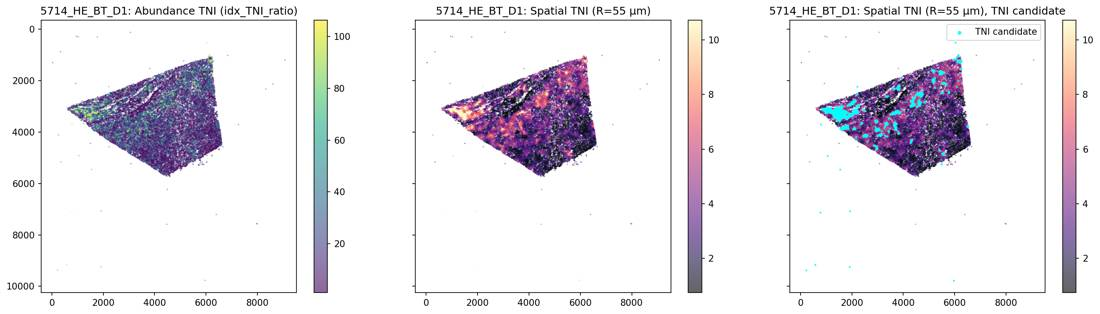

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/5714_HE_BT_D1_TNI_abundance_vs_spatial.png


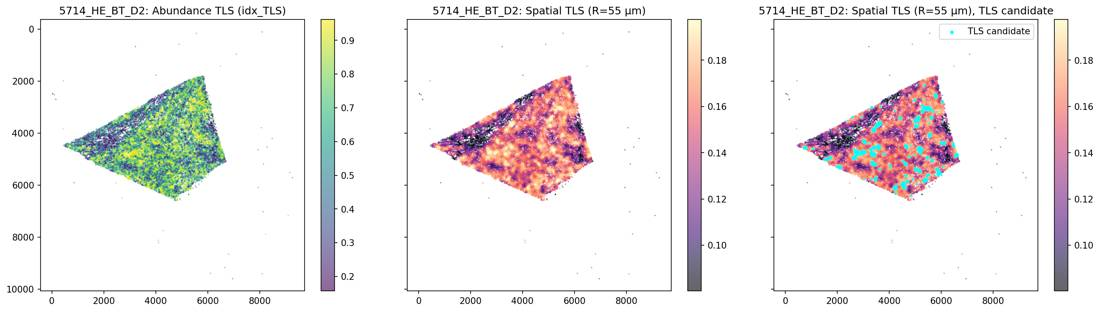

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/5714_HE_BT_D2_TLS_abundance_vs_spatial.png


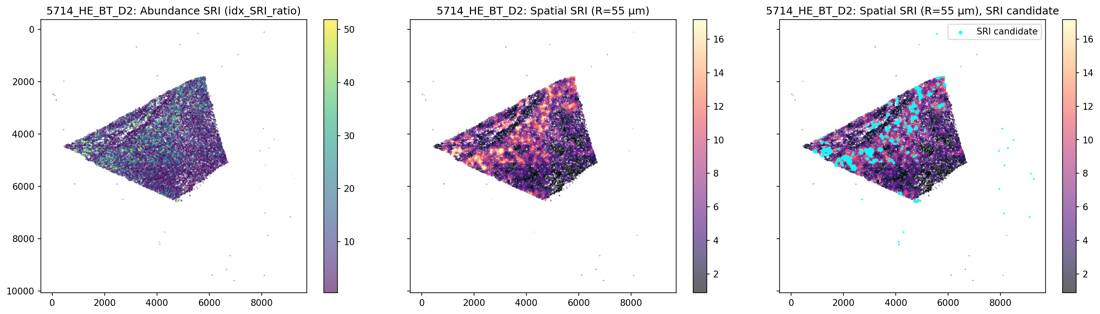

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/5714_HE_BT_D2_SRI_abundance_vs_spatial.png


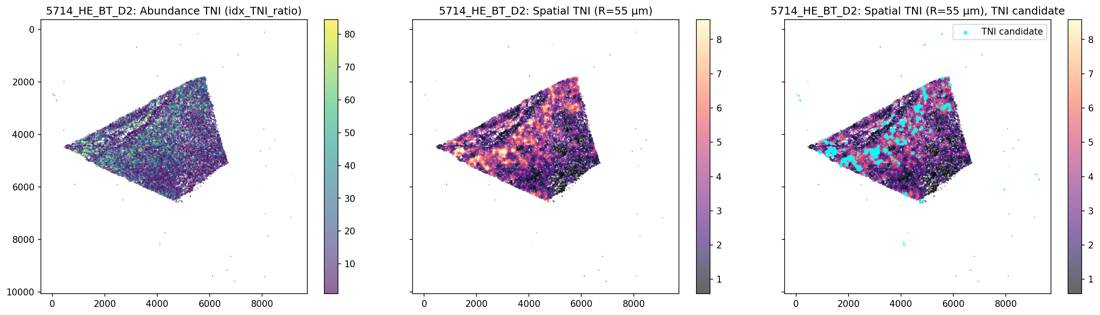

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/5714_HE_BT_D2_TNI_abundance_vs_spatial.png


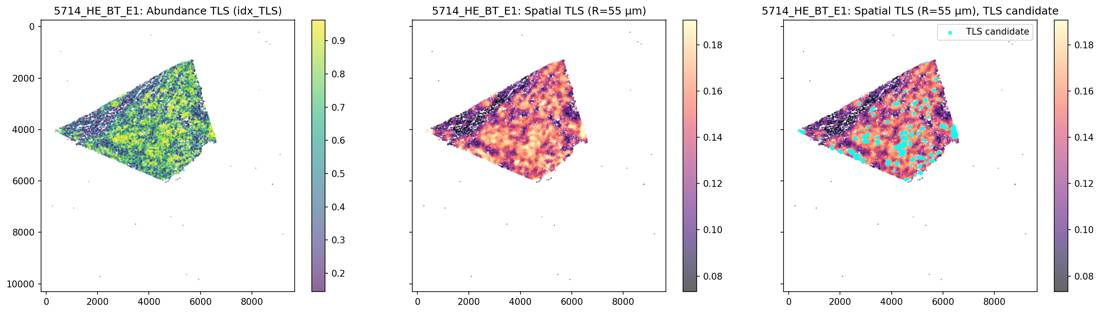

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/5714_HE_BT_E1_TLS_abundance_vs_spatial.png


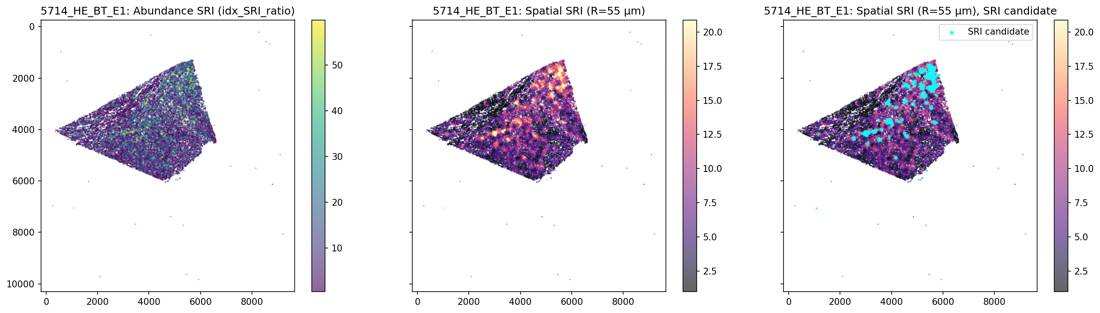

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/5714_HE_BT_E1_SRI_abundance_vs_spatial.png


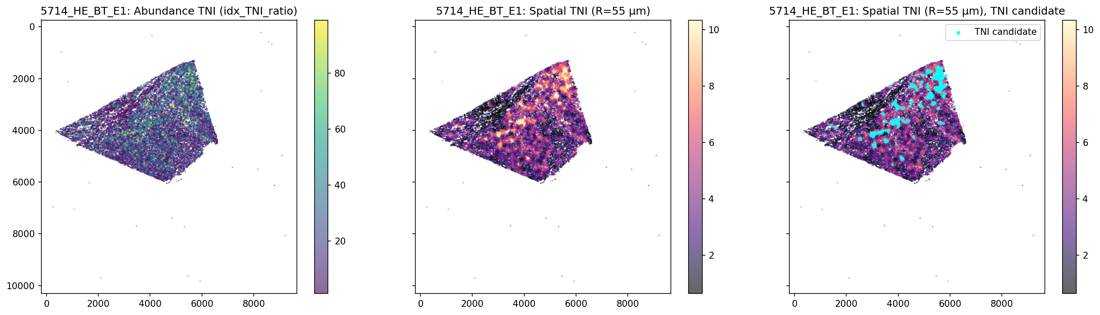

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/5714_HE_BT_E1_TNI_abundance_vs_spatial.png


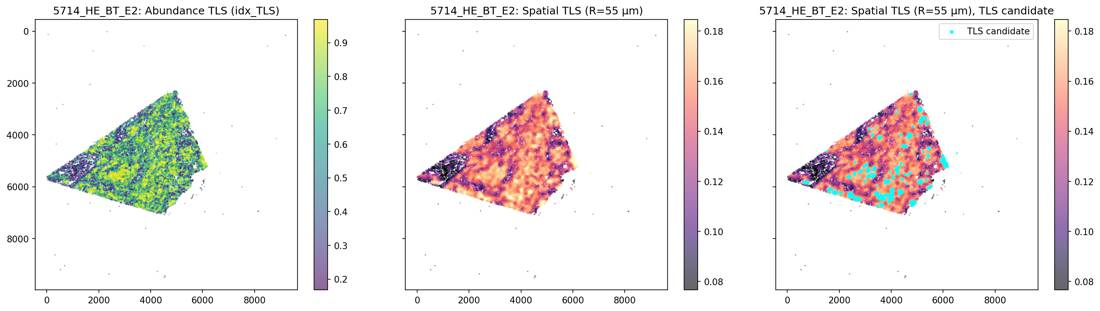

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/5714_HE_BT_E2_TLS_abundance_vs_spatial.png


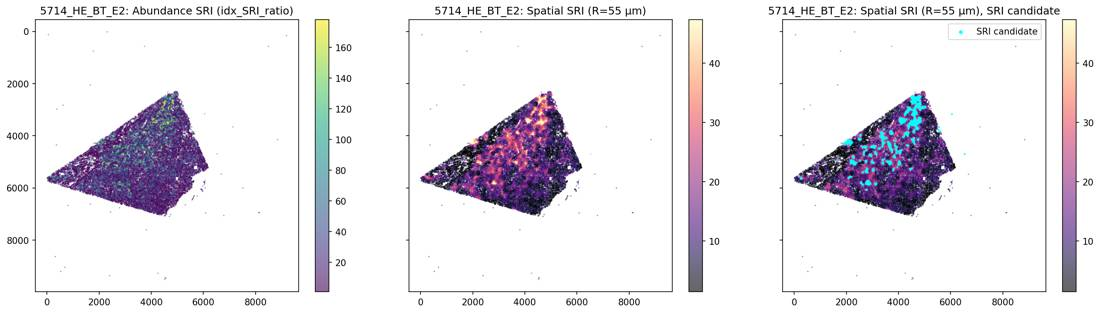

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/5714_HE_BT_E2_SRI_abundance_vs_spatial.png


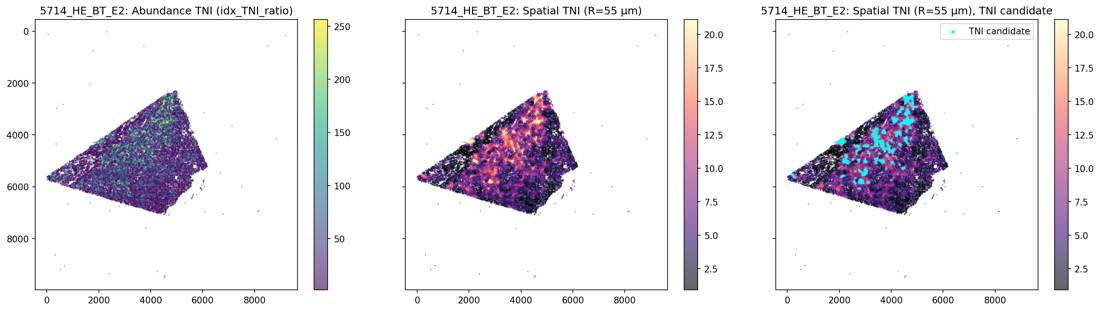

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/5714_HE_BT_E2_TNI_abundance_vs_spatial.png


In [4]:
import numpy as np

missing = [s for s in group if not sample_paths(s)["pred"].is_file()]
if missing:
    raise FileNotFoundError(
        f"No predictions yet for {PATIENT}: "
        + ", ".join(missing)
        + f". Run: SAMPLE={PATIENT} bash code/External_val/BRCA_ST/demo.sh all"
    )
display(Markdown(f"## {PATIENT} — TLS / SRI / TNI"))
frames = {}
for sample in group:
    paths = sample_paths(sample)
    niche_path = paths["pred"].with_name(f"{sample}_niche_indices.h5ad")
    mpp = float(geometry(sample)["mpp_um"])
    if niche_path.is_file() and not RECOMPUTE_NICHE:
        cached = ad.read_h5ad(niche_path)
        df = cached.obs.copy()
        xy = np.asarray(cached.obsm["spatial_HE"], dtype=np.float64)
        df["coord_x"] = xy[:, 0]
        df["coord_y"] = xy[:, 1]
        print(f"[niche] cache {niche_path.name}  n={len(df):,}  µm/px={mpp:.4f}")
    else:
        probs, class_names = ensure_l2_probs(sample)
        absent = hni.missing_index_cell_types(class_names, BRCA_ST_NICHE)
        if absent:
            raise RuntimeError(f"{sample} missing niche compartments: {absent}")
        pred = ad.read_h5ad(paths["pred"])
        coords = np.asarray(pred.obsm["spatial_HE"], dtype=np.float64)
        df = pred.obs.copy()
        df["coord_x"] = coords[:, 0]
        df["coord_y"] = coords[:, 1]
        df = hni.add_abundance_indices(df, probs, class_names, BRCA_ST_NICHE)
        df = hni.add_spatial_indices(
            df, probs, class_names, coords, BRCA_ST_NICHE,
            radius_um=TLS_RADIUS_UM,
            um_per_pixel=mpp,
        )
        out = ad.AnnData(obs=df.drop(columns=["coord_x", "coord_y"]))
        out.obsm["spatial_HE"] = coords
        out.uns["tls_radius_um"] = TLS_RADIUS_UM
        out.uns["um_per_px"] = mpp
        out.write_h5ad(niche_path)
        print(f"[niche] wrote {niche_path}  n={len(df):,}")
    frames[sample] = df
    print(f"  TLS hotspot: {hni.summarize_tls_hotspots(df)}")
    print(
        f"  mean TLS={df['idx_TLS'].mean():.3f}  TLS_spatial={df['idx_TLS_spatial'].mean():.3f}  "
        f"SRI={df['idx_SRI_ratio'].mean():.3f}  TNI={df['idx_TNI_ratio'].mean():.3f}"
    )

def tls_score_row(df, sample: str) -> dict:
    a = df["idx_TLS"].to_numpy(dtype=float)
    s = df["idx_TLS_spatial"].to_numpy(dtype=float)
    a_hi = a >= np.percentile(a, 95)
    s_hi = df["tls_candidate"].fillna(False).astype(bool).to_numpy()
    inter = int(np.logical_and(a_hi, s_hi).sum())
    union = int(np.logical_or(a_hi, s_hi).sum())
    n_a = int(a_hi.sum())
    return {
        "sample": sample,
        "n": int(len(df)),
        "TLS_mean": float(np.mean(a)),
        "TLS_median": float(np.median(a)),
        "TLS_p95": float(np.percentile(a, 95)),
        "TLS_max": float(np.max(a)),
        "TLS_spatial_mean": float(np.mean(s)),
        "TLS_spatial_median": float(np.median(s)),
        "TLS_spatial_p95": float(np.percentile(s, 95)),
        "TLS_spatial_max": float(np.max(s)),
        "pearson": float(np.corrcoef(a, s)[0, 1]),
        "spearman": float(pd.Series(a).corr(pd.Series(s), method="spearman")),
        "top5_jaccard": (inter / union) if union else float("nan"),
        "abundance_top5_also_spatial_top5": (inter / n_a) if n_a else float("nan"),
        "TLS_spatial_mean_in_abundance_top5": float(s[a_hi].mean()) if n_a else float("nan"),
        "TLS_mean_in_spatial_top5": float(a[s_hi].mean()) if s_hi.any() else float("nan"),
    }

tls_quant = pd.DataFrame([tls_score_row(df, sample) for sample, df in frames.items()])
tls_quant_path = fig_dir / f"tls_score_summary_{PATIENT}.csv"
tls_quant.to_csv(tls_quant_path, index=False)
print(tls_quant_path)
display(tls_quant.round(3))

for sample, df in frames.items():
    fig, axes = hdni.plot_tls_abundance_vs_spatial(
        df,
        sample,
        radius_um=TLS_RADIUS_UM,
        use_entropy=False,
        split_spatial_candidates=True,
        point_size=0.15,
        candidate_size=1.2,
        save_path=fig_dir / f"{sample}_TLS_abundance_vs_spatial.png",
    )
    plt.close(fig)
    show_preview(fig_dir / f"{sample}_TLS_abundance_vs_spatial.png")
    for abundance_col, spatial_col, candidate_col, tag in (
        ("idx_SRI_ratio", "idx_SRI_spatial", "sri_candidate", "SRI"),
        ("idx_TNI_ratio", "idx_TNI_spatial", "tni_candidate", "TNI"),
    ):
        fig, axes = hdni.plot_tls_abundance_vs_spatial(
            df,
            sample,
            radius_um=TLS_RADIUS_UM,
            abundance_col=abundance_col,
            spatial_col=spatial_col,
            candidate_col=candidate_col,
            score_name=tag,
            use_entropy=False,
            split_spatial_candidates=True,
            point_size=0.15,
            candidate_size=1.2,
            save_path=fig_dir / f"{sample}_{tag}_abundance_vs_spatial.png",
        )
        plt.close(fig)
        show_preview(fig_dir / f"{sample}_{tag}_abundance_vs_spatial.png")
